# Tutorial 2: Spatial Connectivity

This tutorial covers the spatial connectivity patterns in `braintools.conn`. It focuses on current APIs for distance-dependent sampling, grid/ring topologies, patchy connectivity, and spatial diagnostics.

The key current conventions are:

- represent neuron coordinates as arrays with shape `(n_neurons, n_dimensions)`
- attach distance units with `brainunit`, for example `positions * u.um`
- pass positions with `pre_positions=` and `post_positions=` when generating spatial connectivity
- use `result.get_distances()` to recover per-connection distances
- use profile objects such as `GaussianProfile`, `ExponentialProfile`, and `MexicanHatProfile` through `.probability(distances)`
- use `result.weight2dense()` for matrix visualization instead of rebuilding dense matrices manually

---

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import brainunit as u
from scipy.spatial.distance import cdist

from braintools import conn, visualize as vis
from braintools.init import (
    Constant,
    ExponentialProfile,
    GaussianProfile,
    MexicanHatProfile,
    Normal,
)

rng = np.random.default_rng(42)

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["font.size"] = 10

print("Imports successful")

Imports successful


## 2. Helper Functions

These utilities keep the examples focused on the connectivity API rather than array bookkeeping.

In [2]:
def as_plain(values):
    """Return a NumPy array of mantissas for arrays or brainunit quantities."""
    return np.asarray(u.get_mantissa(values))


def make_grid_positions(rows, cols, spacing=50.0 * u.um):
    """Create row-major 2D grid coordinates with units."""
    spacing_value, unit = u.split_mantissa_unit(spacing)
    y, x = np.mgrid[0:rows, 0:cols]
    positions = np.column_stack([x.ravel(), y.ravel()]) * spacing_value
    return positions * unit


def connection_distances(result):
    """Return per-connection distances as plain numbers in the stored position unit."""
    distances = result.get_distances()
    if distances is None:
        raise ValueError("result does not contain positions")
    return as_plain(distances)


def in_degrees(result):
    return np.bincount(result.post_indices, minlength=result.shape[1])


def out_degrees(result):
    return np.bincount(result.pre_indices, minlength=result.shape[0])


def summarize_result(name, result):
    """Print compact summary information for a ConnectionResult."""
    print(name)
    print("=" * len(name))
    print(f"shape: {result.shape}")
    print(f"connections: {result.n_connections}")
    if result.shape[0] > 0:
        print(f"mean out-degree: {result.n_connections / result.shape[0]:.2f}")
    if result.weights is not None and u.math.size(result.weights) > 0:
        print(f"weight mean: {u.math.mean(result.weights):.3f}")
    if result.delays is not None and u.math.size(result.delays) > 0:
        print(f"delay mean: {u.math.mean(result.delays):.3f}")
    same_numeric_index = int(np.sum(result.pre_indices == result.post_indices))
    print(f"same numeric pre/post index edges: {same_numeric_index}")
    print(f"metadata: {result.metadata}")

---

## 3. Position Arrays

Spatial connectors work with 1D, 2D, or 3D coordinates. Distance calculations use all coordinate dimensions, not only the first two.

In [3]:
n_neurons = 100
positions_2d = rng.uniform(0.0, 1000.0, (n_neurons, 2)) * u.um
positions_1d = np.linspace(0.0, 1000.0, n_neurons).reshape(-1, 1) * u.um
positions_3d = rng.normal(size=(n_neurons, 3)) * np.array([100.0, 100.0, 200.0]) * u.um
positions_grid = make_grid_positions(10, 10, spacing=100.0 * u.um)

print("2D random positions")
print(f"shape: {positions_2d.shape}")
print(f"unit: {u.get_unit(positions_2d)}")
print("first 5 rows:")
print(positions_2d[:5])

print()
print("1D positions")
print(f"shape: {positions_1d.shape}")

print()
print("3D positions")
print(f"shape: {positions_3d.shape}")

2D random positions
shape: (100, 2)
unit: um
first 5 rows:
[[773.95604856 438.87843975]
 [858.59791991 697.36802906]
 [ 94.17734789 975.62235164]
 [761.13970199 786.06430528]
 [128.11363268 450.3859379 ]] um

1D positions
shape: (100, 1)

3D positions
shape: (100, 3)


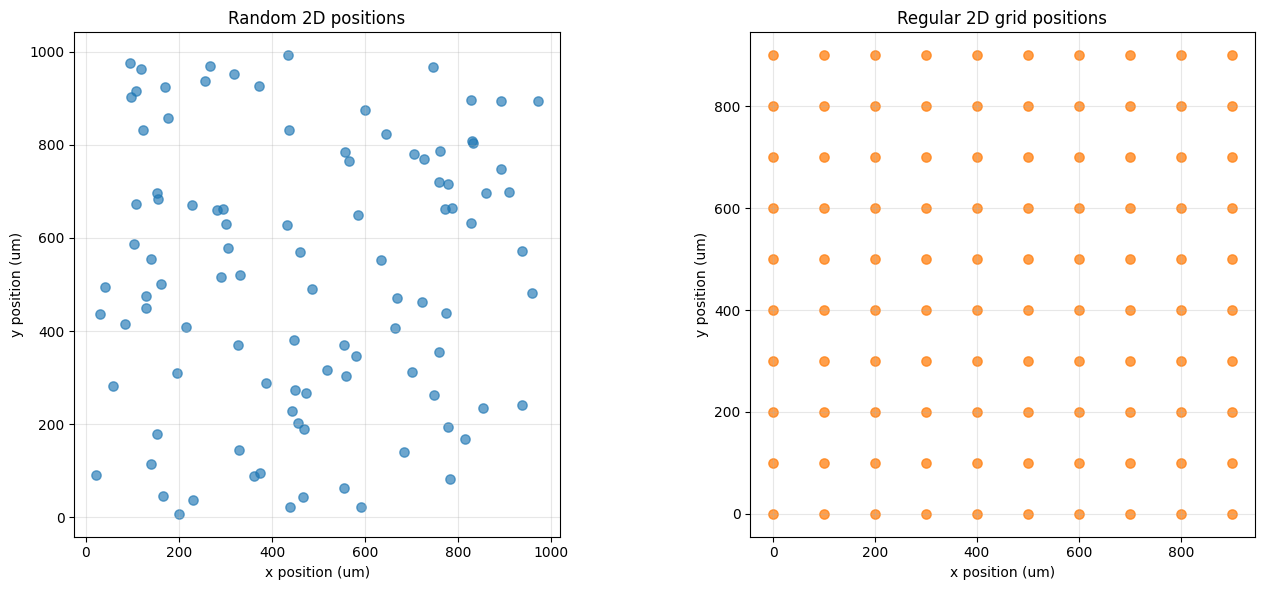

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

random_xy = as_plain(positions_2d)
grid_xy = as_plain(positions_grid)

axes[0].scatter(random_xy[:, 0], random_xy[:, 1], alpha=0.65, s=45)
axes[0].set_xlabel("x position (um)")
axes[0].set_ylabel("y position (um)")
axes[0].set_title("Random 2D positions")
axes[0].grid(True, alpha=0.3)
axes[0].set_aspect("equal")

axes[1].scatter(grid_xy[:, 0], grid_xy[:, 1], alpha=0.75, s=45, color="tab:orange")
axes[1].set_xlabel("x position (um)")
axes[1].set_ylabel("y position (um)")
axes[1].set_title("Regular 2D grid positions")
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

---

## 4. Distance Profiles

A distance profile maps pairwise distances to connection probabilities. The specialized connectors `Gaussian` and `Exponential` require matching profile types, while the general `DistanceDependent` connector accepts any `DistanceProfile` implementation or composition.

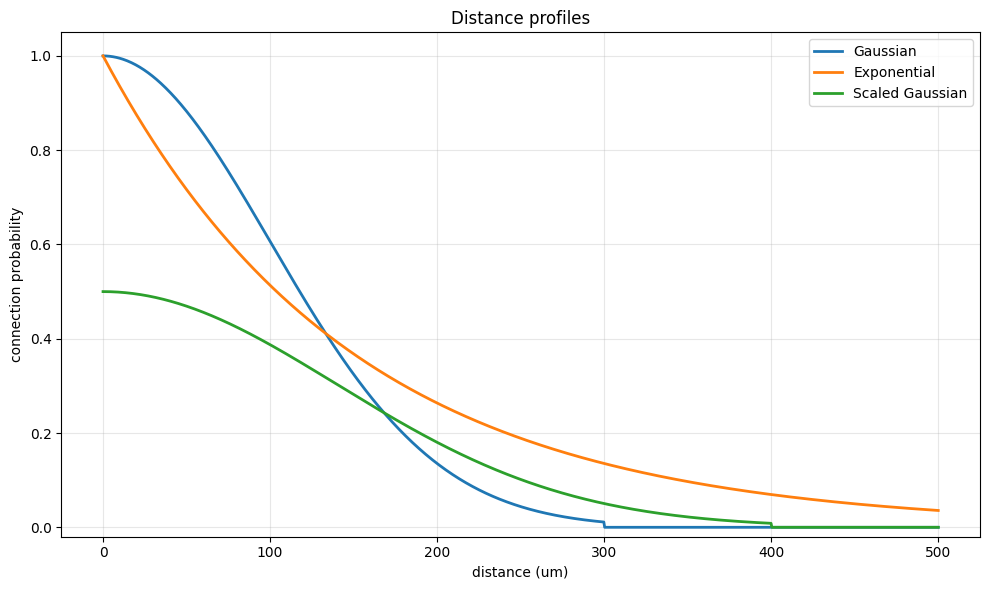

In [5]:
distances = np.linspace(0.0, 500.0, 1000) * u.um
plain_distances = as_plain(distances)

gaussian_profile = GaussianProfile(sigma=100.0 * u.um, max_distance=300.0 * u.um)
exponential_profile = ExponentialProfile(decay_constant=150.0 * u.um, max_distance=500.0 * u.um)
scaled_profile = (GaussianProfile(sigma=140.0 * u.um, max_distance=400.0 * u.um) * 0.5).clip(0.0, 0.5)

profiles = [
    ("Gaussian", gaussian_profile, "tab:blue"),
    ("Exponential", exponential_profile, "tab:orange"),
    ("Scaled Gaussian", scaled_profile, "tab:green"),
]

fig, ax = plt.subplots(figsize=(10, 6))
for label, profile, color in profiles:
    ax.plot(plain_distances, profile.probability(distances), label=label, linewidth=2, color=color)

ax.set_xlabel("distance (um)")
ax.set_ylabel("connection probability")
ax.set_title("Distance profiles")
ax.set_ylim(-0.02, 1.05)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 5. Distance-Dependent Connectivity

`Gaussian` and `Exponential` are typed wrappers around `DistanceDependent`. They compute all pairwise distances from the provided positions, sample connections from the profile probabilities, and return a `ConnectionResult`.

When the same population is used for pre and post positions, self-connections are removed by default. Set `allow_self_connections=True` if autapses are desired.

In [6]:
n_spatial = 200
spatial_positions = rng.uniform(0.0, 1000.0, (n_spatial, 2)) * u.um

gaussian_conn = conn.Gaussian(
    distance_profile=GaussianProfile(sigma=100.0 * u.um, max_distance=300.0 * u.um),
    weight=Constant(1.0 * u.nS),
    seed=42,
)
exponential_conn = conn.Exponential(
    distance_profile=ExponentialProfile(decay_constant=150.0 * u.um, max_distance=500.0 * u.um),
    weight=Constant(1.5 * u.nS),
    seed=42,
)

gaussian_result = gaussian_conn(
    pre_size=n_spatial,
    post_size=n_spatial,
    pre_positions=spatial_positions,
    post_positions=spatial_positions,
)
exponential_result = exponential_conn(
    pre_size=n_spatial,
    post_size=n_spatial,
    pre_positions=spatial_positions,
    post_positions=spatial_positions,
)

summarize_result("Gaussian distance-dependent connectivity", gaussian_result)
print()
summarize_result("Exponential distance-dependent connectivity", exponential_result)

Gaussian distance-dependent connectivity
shape: (200, 200)
connections: 1994
mean out-degree: 9.97
weight mean: 1.000 nS
same numeric pre/post index edges: 0
metadata: {'pattern': 'distance_dependent', 'distance_profile': GaussianProfile(sigma=100. um, max_distance=300. um), 'weight_initialization': Constant(value=1. nS), 'delay_initialization': None}

Exponential distance-dependent connectivity
shape: (200, 200)
connections: 3318
mean out-degree: 16.59
weight mean: 1.500 nS
same numeric pre/post index edges: 0
metadata: {'pattern': 'distance_dependent', 'distance_profile': ExponentialProfile(decay_constant=150. um, max_distance=500. um), 'weight_initialization': Constant(value=1.5 nS), 'delay_initialization': None}


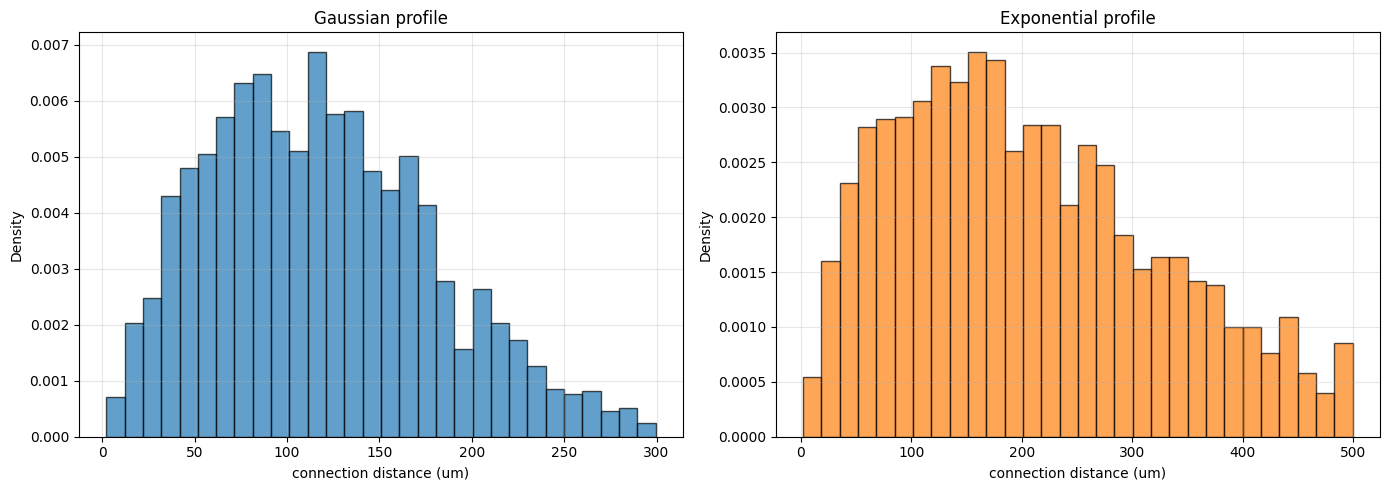

Gaussian mean distance:    118.4 um
Exponential mean distance: 206.0 um


In [7]:
gaussian_distances = connection_distances(gaussian_result)
exponential_distances = connection_distances(exponential_result)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vis.distribution_plot(
    gaussian_distances,
    bins=30,
    alpha=0.7,
    colors=["tab:blue"],
    edgecolor="black",
    ax=axes[0],
    xlabel="connection distance (um)",
    title="Gaussian profile",
)
vis.distribution_plot(
    exponential_distances,
    bins=30,
    alpha=0.7,
    colors=["tab:orange"],
    edgecolor="black",
    ax=axes[1],
    xlabel="connection distance (um)",
    title="Exponential profile",
)

plt.tight_layout()
plt.show()

print(f"Gaussian mean distance:    {np.mean(gaussian_distances):.1f} um")
print(f"Exponential mean distance: {np.mean(exponential_distances):.1f} um")

### Precomputed Distances

For repeated experiments over fixed positions, precompute the pairwise distance matrix and pass it with `distances=`. If the matrix represents a recurrent same-population layout, also pass the positions so the connector can identify and remove self-connections by default.

In [8]:
position_values = as_plain(spatial_positions)
precomputed_distances = cdist(position_values, position_values) * u.um

precomputed_conn = conn.DistanceDependent(
    distance_profile=GaussianProfile(sigma=100.0 * u.um, max_distance=300.0 * u.um),
    weight=Constant(1.0 * u.nS),
    seed=42,
)
precomputed_result = precomputed_conn(
    pre_size=n_spatial,
    post_size=n_spatial,
    pre_positions=spatial_positions,
    post_positions=spatial_positions,
    distances=precomputed_distances,
)

print(f"same edge count as position-based Gaussian: {precomputed_result.n_connections == gaussian_result.n_connections}")
print(f"self-connections after recurrent detection: {int(np.sum(precomputed_result.pre_indices == precomputed_result.post_indices))}")

same edge count as position-based Gaussian: True
self-connections after recurrent detection: 0


### Custom and Built-In Non-Gaussian Profiles

`braintools.init` also provides non-Gaussian profiles such as `MexicanHatProfile`, which can be used directly with `DistanceDependent`.

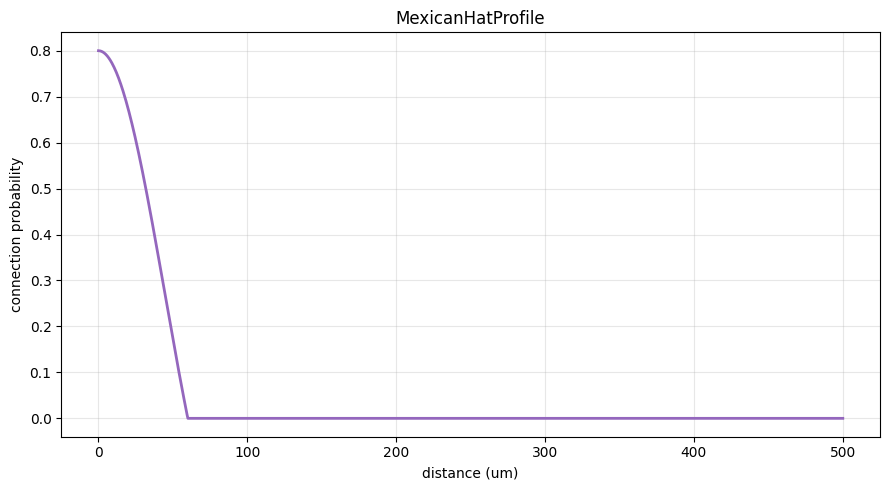

Mexican-hat distance-dependent connectivity
shape: (200, 200)
connections: 134
mean out-degree: 0.67
weight mean: 0.986 nS
same numeric pre/post index edges: 0
metadata: {'pattern': 'distance_dependent', 'distance_profile': MexicanHatProfile(sigma=60. um, amplitude=0.8, max_distance=240. um), 'weight_initialization': Normal(mean=1. nS, std=0.2 nS), 'delay_initialization': None}


In [9]:
mexican_hat_profile = MexicanHatProfile(
    sigma=60.0 * u.um,
    amplitude=0.8,
    max_distance=240.0 * u.um,
)

mexican_hat_result = conn.DistanceDependent(
    distance_profile=mexican_hat_profile,
    weight=Normal(mean=1.0 * u.nS, std=0.2 * u.nS),
    seed=43,
)(
    pre_size=n_spatial,
    post_size=n_spatial,
    pre_positions=spatial_positions,
    post_positions=spatial_positions,
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(plain_distances, mexican_hat_profile.probability(distances), color="tab:purple", linewidth=2)
ax.set_xlabel("distance (um)")
ax.set_ylabel("connection probability")
ax.set_title("MexicanHatProfile")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

summarize_result("Mexican-hat distance-dependent connectivity", mexican_hat_result)

---

## 6. Spatial Topologies

`Ring` and `Grid2d` generate deterministic topologies from population sizes rather than arbitrary coordinate arrays.

In [10]:
ring = conn.Ring(neighbors=3, weight=Constant(1.0 * u.nS), bidirectional=True)
ring_result = ring(pre_size=100, post_size=100)

summarize_result("Ring topology", ring_result)
print(f"expected connections: {100 * 3 * 2}")

Ring topology
shape: (100, 100)
connections: 600
mean out-degree: 6.00


weight mean: 1.000 nS
same numeric pre/post index edges: 0
metadata: {'pattern': 'ring', 'neighbors': 3, 'bidirectional': True}
expected connections: 600


In [11]:
grid_von_neumann = conn.Grid2d(connectivity="von_neumann", weight=Constant(1.0 * u.nS), periodic=False)
grid_moore = conn.Grid2d(connectivity="moore", weight=Constant(1.5 * u.nS), periodic=False)

result_von_neumann = grid_von_neumann(pre_size=(10, 10), post_size=(10, 10))
result_moore = grid_moore(pre_size=(10, 10), post_size=(10, 10))

summarize_result("Grid2d von_neumann", result_von_neumann)
print()
summarize_result("Grid2d moore", result_moore)

Grid2d von_neumann
shape: (100, 100)
connections: 360
mean out-degree: 3.60
weight mean: 1.000 nS
same numeric pre/post index edges: 0
metadata: {'pattern': 'grid', 'grid_shape': (10, 10), 'connectivity': 'von_neumann', 'periodic': False}

Grid2d moore
shape: (100, 100)
connections: 684
mean out-degree: 6.84
weight mean: 1.500 nS
same numeric pre/post index edges: 0
metadata: {'pattern': 'grid', 'grid_shape': (10, 10), 'connectivity': 'moore', 'periodic': False}


In [12]:
nonperiodic = conn.Grid2d(connectivity="moore", periodic=False)(pre_size=(8, 8), post_size=(8, 8))
periodic = conn.Grid2d(connectivity="moore", periodic=True)(pre_size=(8, 8), post_size=(8, 8))

in_nonperiodic = in_degrees(nonperiodic)
in_periodic = in_degrees(periodic)

print("Moore grid boundary comparison")
print(f"non-periodic connections: {nonperiodic.n_connections}")
print(f"non-periodic in-degree range: {in_nonperiodic.min()} to {in_nonperiodic.max()}")
print(f"periodic connections:     {periodic.n_connections}")
print(f"periodic in-degree range: {in_periodic.min()} to {in_periodic.max()}")

Moore grid boundary comparison
non-periodic connections: 420
non-periodic in-degree range: 3 to 8
periodic connections:     512
periodic in-degree range: 8 to 8


---

## 7. Clustered and Patchy Connectivity

`ClusteredRandom` raises the base connection probability inside a spatial radius. `RadialPatches` samples patch centers for each presynaptic neuron and connects to nearby postsynaptic neurons inside each selected patch.

Both connectors accept `allow_self_connections`. It defaults to `False`, so self-connections are dropped when the same population is passed as pre and post.

In [13]:
n_cluster = 300
cluster_positions = rng.uniform(0.0, 1000.0, (n_cluster, 2)) * u.um

clustered = conn.ClusteredRandom(
    prob=0.05,
    cluster_radius=100.0 * u.um,
    cluster_factor=5.0,
    weight=Constant(1.0 * u.nS),
    seed=42,
)
clustered_result = clustered(
    pre_size=n_cluster,
    post_size=n_cluster,
    pre_positions=cluster_positions,
    post_positions=cluster_positions,
)

baseline_random = conn.Random(prob=0.05, seed=42)
baseline_result = baseline_random(
    pre_size=n_cluster,
    post_size=n_cluster,
    pre_positions=cluster_positions,
    post_positions=cluster_positions,
)

summarize_result("ClusteredRandom", clustered_result)
print()
summarize_result("Baseline Random", baseline_result)
print()
print(f"connection count increase: {(clustered_result.n_connections / baseline_result.n_connections - 1) * 100:.1f}%")

ClusteredRandom
shape: (300, 300)
connections: 4980
mean out-degree: 16.60


weight mean: 1.000 nS


same numeric pre/post index edges: 0
metadata: {'pattern': 'clustered_random', 'prob': 0.05, 'cluster_radius': Quantity(100., "um"), 'allow_self_connections': False}

Baseline Random
shape: (300, 300)
connections: 4451
mean out-degree: 14.84
same numeric pre/post index edges: 0
metadata: {'pattern': 'random', 'probability': 0.05, 'allow_self_connections': False, 'weight_initialization': None, 'delay_initialization': None}

connection count increase: 11.9%


In [14]:
patchy = conn.RadialPatches(
    patch_radius=60.0 * u.um,
    n_patches=3,
    prob=0.7,
    weight=Normal(mean=1.5 * u.nS, std=0.3 * u.nS),
    seed=42,
)
patchy_result = patchy(
    pre_size=n_cluster,
    post_size=n_cluster,
    pre_positions=cluster_positions,
    post_positions=cluster_positions,
)

summarize_result("RadialPatches", patchy_result)

RadialPatches
shape: (300, 300)
connections: 2485
mean out-degree: 8.28
weight mean: 1.494 nS
same numeric pre/post index edges: 0
metadata: {'pattern': 'radial_patches', 'patch_radius': Quantity(60., "um"), 'n_patches': 3}


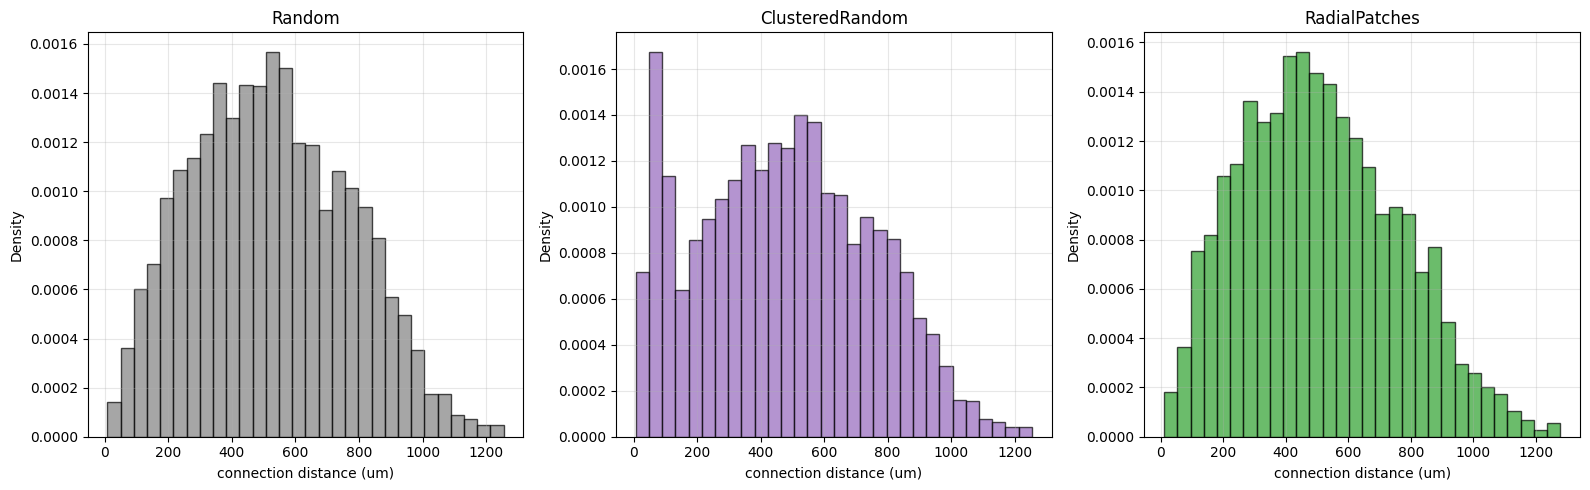

Mean connection distances
random:          523.4 um
clustered:       475.1 um
radial patches:  510.6 um


In [15]:
dist_random = connection_distances(baseline_result)
dist_clustered = connection_distances(clustered_result)
dist_patchy = connection_distances(patchy_result)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, label, values, color in [
    (axes[0], "Random", dist_random, "gray"),
    (axes[1], "ClusteredRandom", dist_clustered, "tab:purple"),
    (axes[2], "RadialPatches", dist_patchy, "tab:green"),
]:
    vis.distribution_plot(
        values,
        bins=30,
        alpha=0.7,
        colors=[color],
        edgecolor="black",
        ax=ax,
        xlabel="connection distance (um)",
        title=label,
    )

plt.tight_layout()
plt.show()

print("Mean connection distances")
print(f"random:          {np.mean(dist_random):.1f} um")
print(f"clustered:       {np.mean(dist_clustered):.1f} um")
print(f"radial patches:  {np.mean(dist_patchy):.1f} um")

---

## 8. Spatial Visualization

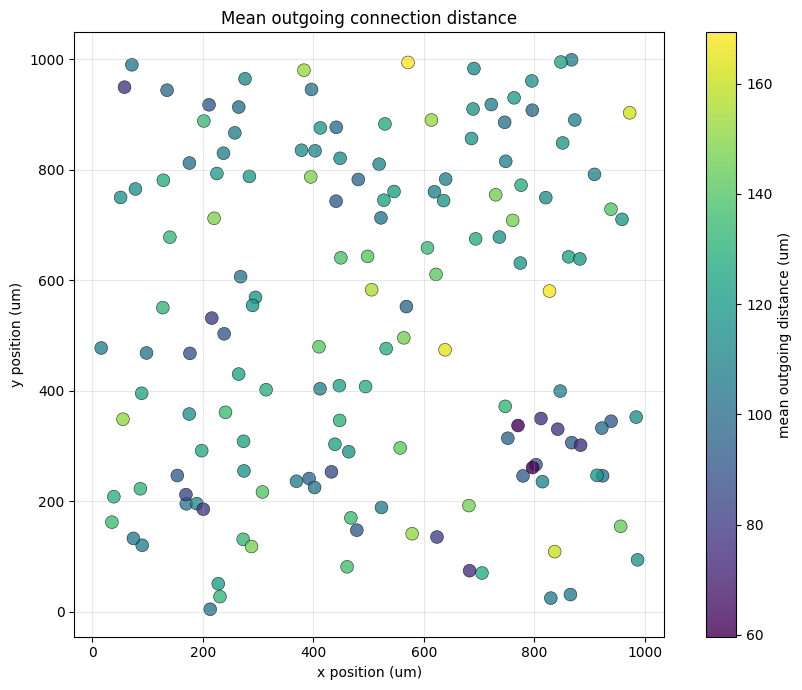

sources with at least one outgoing connection: 150 / 150


In [16]:
def mean_outgoing_distance(result):
    """Mean outgoing connection distance for each presynaptic neuron."""
    distances = connection_distances(result)
    means = np.zeros(result.shape[0])
    counts = np.zeros(result.shape[0], dtype=int)
    np.add.at(means, result.pre_indices, distances)
    np.add.at(counts, result.pre_indices, 1)
    connected = counts > 0
    means[connected] = means[connected] / counts[connected]
    return means, connected


n_viz = 150
viz_positions = rng.uniform(0.0, 1000.0, (n_viz, 2)) * u.um
viz_result = conn.Gaussian(
    distance_profile=GaussianProfile(sigma=100.0 * u.um, max_distance=300.0 * u.um),
    weight=Constant(1.0 * u.nS),
    seed=42,
)(
    pre_size=n_viz,
    post_size=n_viz,
    pre_positions=viz_positions,
    post_positions=viz_positions,
)

mean_dists, connected_sources = mean_outgoing_distance(viz_result)
viz_xy = as_plain(viz_positions)

fig, ax = plt.subplots(figsize=(9, 7))
scatter = ax.scatter(
    viz_xy[:, 0],
    viz_xy[:, 1],
    c=mean_dists,
    s=85,
    cmap="viridis",
    alpha=0.8,
    edgecolors="black",
    linewidth=0.4,
)
plt.colorbar(scatter, label="mean outgoing distance (um)", ax=ax)
ax.set_xlabel("x position (um)")
ax.set_ylabel("y position (um)")
ax.set_title("Mean outgoing connection distance")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"sources with at least one outgoing connection: {int(np.sum(connected_sources))} / {n_viz}")

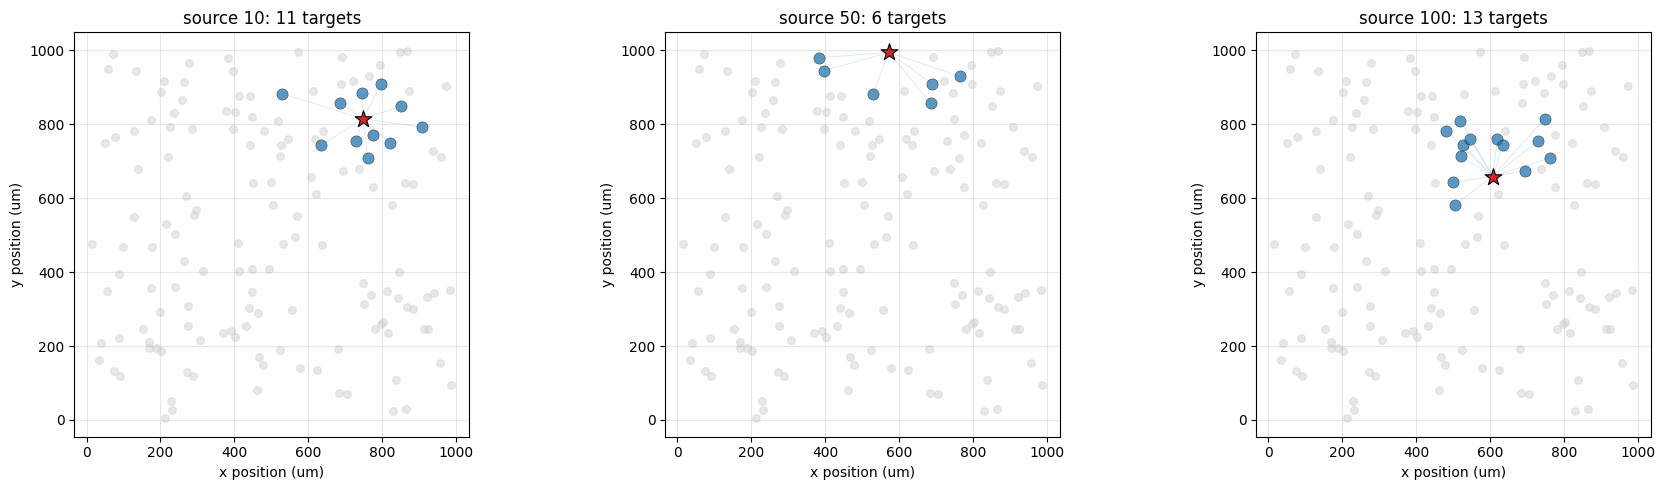

In [17]:
example_neurons = [10, 50, 100]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, neuron_id in zip(axes, example_neurons):
    ax.scatter(viz_xy[:, 0], viz_xy[:, 1], c="lightgray", s=30, alpha=0.5, zorder=1)
    ax.scatter(
        viz_xy[neuron_id, 0],
        viz_xy[neuron_id, 1],
        c="tab:red",
        s=160,
        marker="*",
        zorder=3,
        edgecolors="black",
        linewidth=0.8,
    )

    target_ids = viz_result.post_indices[viz_result.pre_indices == neuron_id]
    if target_ids.size:
        ax.scatter(
            viz_xy[target_ids, 0],
            viz_xy[target_ids, 1],
            c="tab:blue",
            s=65,
            alpha=0.7,
            zorder=2,
            edgecolors="black",
            linewidth=0.4,
        )
        for target_id in target_ids:
            ax.plot(
                [viz_xy[neuron_id, 0], viz_xy[target_id, 0]],
                [viz_xy[neuron_id, 1], viz_xy[target_id, 1]],
                color="tab:blue",
                alpha=0.18,
                linewidth=0.6,
                zorder=0,
            )

    ax.set_xlabel("x position (um)")
    ax.set_ylabel("y position (um)")
    ax.set_title(f"source {neuron_id}: {target_ids.size} targets")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

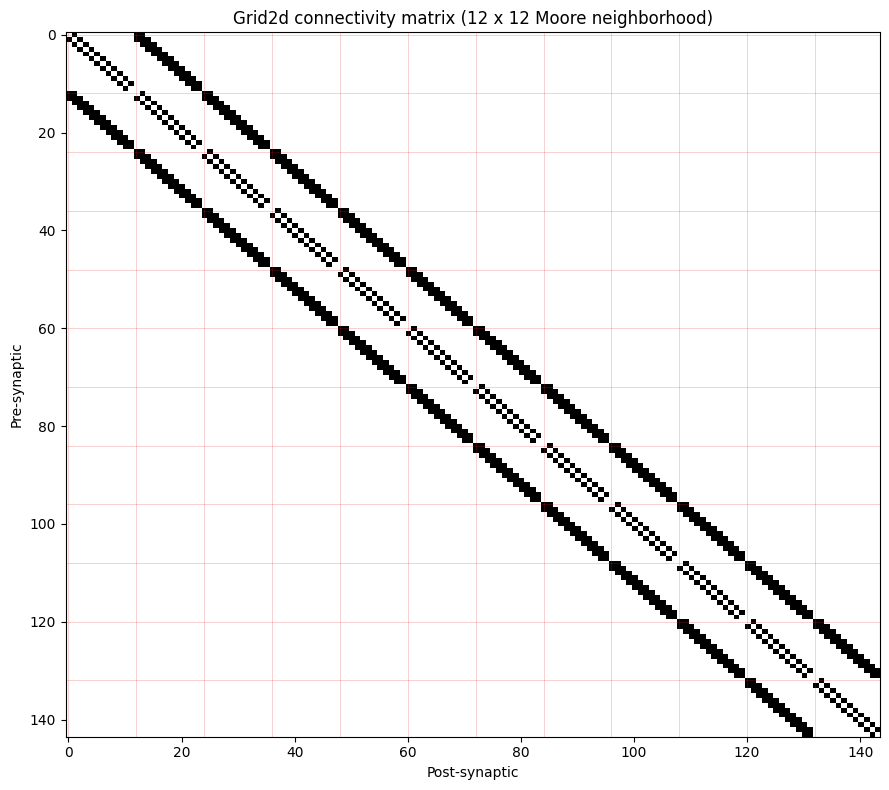

In [18]:
grid_small = conn.Grid2d(connectivity="moore", weight=Constant(1.0 * u.nS), periodic=False)
grid_small_result = grid_small(pre_size=(12, 12), post_size=(12, 12))
grid_matrix = as_plain(grid_small_result.weight2dense())

fig, ax = plt.subplots(figsize=(9, 8))
vis.connectivity_matrix(
    grid_matrix,
    cmap="binary",
    center_zero=False,
    show_colorbar=False,
    ax=ax,
    title="Grid2d connectivity matrix (12 x 12 Moore neighborhood)",
)
for edge in range(0, grid_matrix.shape[0], 12):
    ax.axhline(edge, color="tab:red", linewidth=0.5, alpha=0.3)
    ax.axvline(edge, color="tab:red", linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

### Degree Distributions

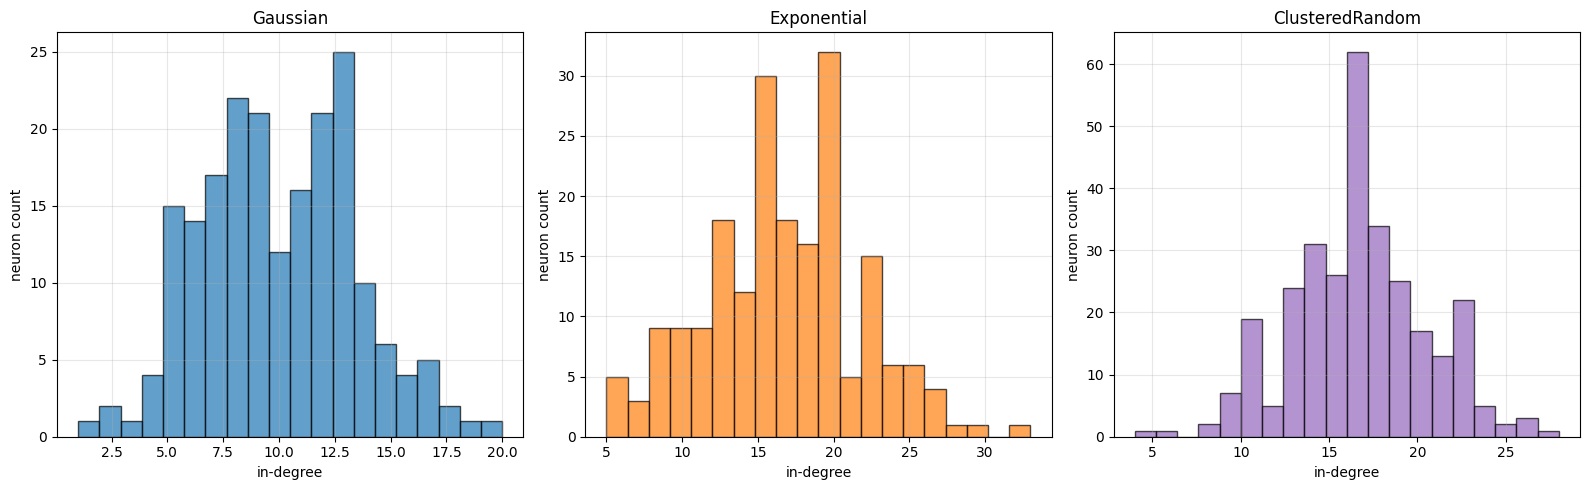

Gaussian in-degree CV: 0.361
Exponential in-degree CV: 0.307
ClusteredRandom in-degree CV: 0.231


In [19]:
degree_samples = [
    ("Gaussian", in_degrees(gaussian_result), "tab:blue"),
    ("Exponential", in_degrees(exponential_result), "tab:orange"),
    ("ClusteredRandom", in_degrees(clustered_result), "tab:purple"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (label, degrees, color) in zip(axes, degree_samples):
    vis.distribution_plot(
        degrees,
        bins=20,
        density=False,
        alpha=0.7,
        colors=[color],
        edgecolor="black",
        ax=ax,
        xlabel="in-degree",
        ylabel="neuron count",
        title=label,
    )

plt.tight_layout()
plt.show()

for label, degrees, _ in degree_samples:
    cv = np.std(degrees) / np.mean(degrees)
    print(f"{label} in-degree CV: {cv:.3f}")

---

## 9. Worked Analyses

### 9.1 Spatial Clustering Index

The index below compares observed mean connection length with the mean length of all possible non-self pairs. Positive values indicate shorter-than-random local connectivity.

In [20]:
def spatial_clustering_index(result):
    observed = connection_distances(result)
    if observed.size == 0:
        return np.nan
    if result.pre_positions is None or result.post_positions is None:
        raise ValueError("positions are required")

    pre_values, unit = u.split_mantissa_unit(result.pre_positions)
    post_values = u.Quantity(result.post_positions).to(unit).mantissa
    possible = cdist(pre_values, post_values)

    if result.shape[0] == result.shape[1] and np.array_equal(pre_values, post_values):
        possible = possible[~np.eye(result.shape[0], dtype=bool)]
    else:
        possible = possible.ravel()

    expected_mean = np.mean(possible)
    return 1.0 - np.mean(observed) / expected_mean


for label, sample in [
    ("Gaussian", gaussian_result),
    ("Exponential", exponential_result),
    ("Random", baseline_result),
    ("ClusteredRandom", clustered_result),
    ("RadialPatches", patchy_result),
]:
    print(f"{label}: {spatial_clustering_index(sample):.3f}")

Gaussian: 0.781
Exponential: 0.618
Random: 0.004
ClusteredRandom: 0.096
RadialPatches: 0.028


### 9.2 Topographic Projection

A topographic projection connects two populations with different sizes and positions. Nearby source and target coordinates are more likely to connect.

In [21]:
def create_topographic_map(source_positions, target_positions, sigma, weight_init, seed=0):
    """Create a distance-dependent projection between two coordinate maps."""
    pattern = conn.Gaussian(
        distance_profile=GaussianProfile(sigma=sigma, max_distance=3 * sigma),
        weight=weight_init,
        seed=seed,
    )
    return pattern(
        pre_size=len(source_positions),
        post_size=len(target_positions),
        pre_positions=source_positions,
        post_positions=target_positions,
    )


retina_positions = make_grid_positions(10, 10, spacing=50.0 * u.um)
v1_positions = make_grid_positions(15, 15, spacing=(50.0 * 9 / 14) * u.um)

topographic_result = create_topographic_map(
    retina_positions,
    v1_positions,
    sigma=60.0 * u.um,
    weight_init=Constant(1.0 * u.nS),
    seed=42,
)

summarize_result("Topographic projection", topographic_result)
print(f"mean projection distance: {np.mean(connection_distances(topographic_result)):.1f} um")

Topographic projection
shape: (100, 225)
connections: 1665
mean out-degree: 16.65
weight mean: 1.000 nS
same numeric pre/post index edges: 9
metadata: {'pattern': 'distance_dependent', 'distance_profile': GaussianProfile(sigma=60. um, max_distance=180. um), 'weight_initialization': Constant(value=1. nS), 'delay_initialization': None}
mean projection distance: 68.1 um


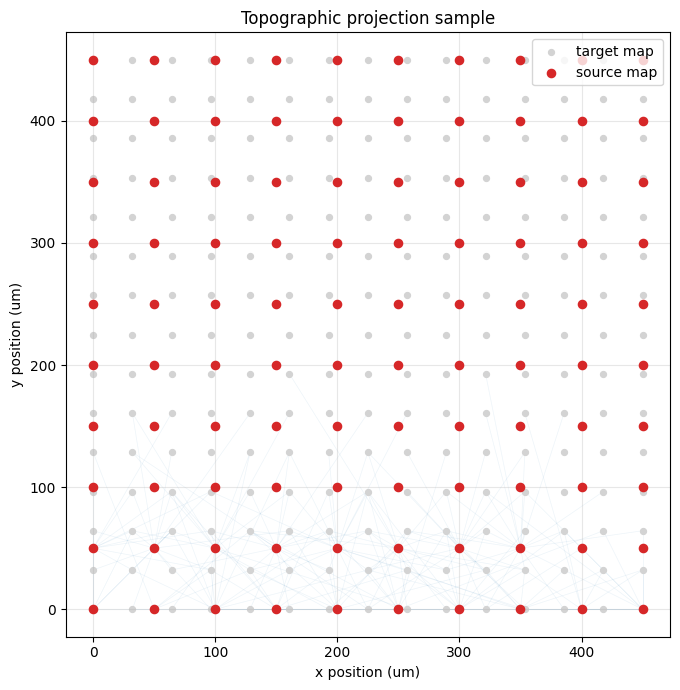

In [22]:
retina_xy = as_plain(retina_positions)
v1_xy = as_plain(v1_positions)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(v1_xy[:, 0], v1_xy[:, 1], s=18, c="lightgray", label="target map", zorder=1)
ax.scatter(retina_xy[:, 0], retina_xy[:, 1], s=35, c="tab:red", label="source map", zorder=2)

shown_edges = min(250, topographic_result.n_connections)
for pre_id, post_id in zip(topographic_result.pre_indices[:shown_edges], topographic_result.post_indices[:shown_edges]):
    ax.plot(
        [retina_xy[pre_id, 0], v1_xy[post_id, 0]],
        [retina_xy[pre_id, 1], v1_xy[post_id, 1]],
        color="tab:blue",
        alpha=0.08,
        linewidth=0.5,
        zorder=0,
    )

ax.set_xlabel("x position (um)")
ax.set_ylabel("y position (um)")
ax.set_title("Topographic projection sample")
ax.set_aspect("equal")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 10. Key Takeaways

- Spatial connectors need positions or a precomputed distance matrix.
- `Gaussian` and `Exponential` require `GaussianProfile` and `ExponentialProfile` respectively; use `DistanceDependent` for custom or composed profiles.
- `result.get_distances()` is the preferred way to inspect realized connection lengths.
- Same-population distance-dependent, clustered, and radial-patch connectors remove self-connections by default; cross-population projections do not treat equal numeric indices as autapses.
- `Ring` and `Grid2d` are deterministic topology generators, while `Gaussian`, `Exponential`, `ClusteredRandom`, and `RadialPatches` are stochastic and should usually be seeded in tutorials.